# Customer Churn: Exploratory Data Analysis (EDA)

**Goal:** understand *who* churns and *why*, so the Power BI dashboard can tell a clear story.
**Input:** the cleaned dataset from my cleaning notebook (`customer_churn.csv`).
**Output:** a list of key findings and the columns/segments to build in Power BI.

## Business questions I want to answer
1. What is the overall churn rate, and is the data balanced?
2. Which customer groups (contract, internet service, tech support, gender) churn the most?
3. Do new customers churn faster than long-term ones?
4. Does the monthly price relate to churn?
5. Which segments are the highest risk, and how much revenue is at risk?

## Workflow
Setup → Load & check → Baseline → One column at a time → Column vs churn → Relationships → Segments → Key findings

## 1. Setup

In [1]:
# importing data analysis and visualization libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")          # clean look for every chart
pd.set_option("display.max_columns", None)  # show all columns when printing tables

## 2. Load the cleaned data and run sanity checks
Before analysing anything I confirm the cleaned file is what I expect: right size, right types, no missing values, no duplicates.

In [2]:
# loading the cleaned dataset (relative path so the notebook runs on any computer)
customer_churn = pd.read_csv("customer_churn.csv")
customer_churn.head()

,CustomerID,Age,Gender,Tenure,MonthlyCharges,ContractType,InternetService,TotalCharges,TechSupport,Churn,Churn_Flag
0,1,49,Male,4,88.35,Month-to-Month,Fiber Optic,353.40,Yes,Yes,1
1,2,43,Male,0,36.67,Month-to-Month,Fiber Optic,0.00,Yes,Yes,1
2,3,51,Female,2,63.79,Month-to-Month,Fiber Optic,127.58,No,Yes,1
3,4,60,Female,8,102.34,One-Year,DSL,818.72,Yes,Yes,1
4,5,42,Male,32,69.01,Month-to-Month,No Internet,2208.32,No,Yes,1


In [3]:
# size of the data and the data type of each column
print("Rows, columns:", customer_churn.shape)
customer_churn.info()

Rows, columns: (1000, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerID       1000 non-null   int64  
 1   Age              1000 non-null   int64  
 2   Gender           1000 non-null   object 
 3   Tenure           1000 non-null   int64  
 4   MonthlyCharges   1000 non-null   float64
 5   ContractType     1000 non-null   object 
 6   InternetService  1000 non-null   object 
 7   TotalCharges     1000 non-null   float64
 8   TechSupport      1000 non-null   object 
 9   Churn            1000 non-null   object 
 10  Churn_Flag       1000 non-null   int64  
dtypes: float64(2), int64(4), object(5)
memory usage: 86.1+ KB


In [4]:
# sanity checks: no missing values, no duplicate rows, no duplicate customer IDs
print("Missing values:", customer_churn.isnull().sum().sum())
print("Duplicate rows:", customer_churn.duplicated().sum())
print("Duplicate customer IDs:", customer_churn["CustomerID"].duplicated().sum())

Missing values: 0
Duplicate rows: 0
Duplicate customer IDs: 0


**Observation:** the data has no missing values or duplicates, and the data types are correct, so it is ready for analysis.
`Churn` (Yes/No) is the text version of the target and `Churn_Flag` (1/0) is the numeric version I will use for calculating rates.

In [5]:
# lists of columns by type, so I do not repeat the names in every cell
cat_cols = ["Gender", "ContractType", "InternetService", "TechSupport"]
num_cols = ["Age", "Tenure", "MonthlyCharges", "TotalCharges"]

## 3. Baseline: the overall churn rate
Every other number in this notebook gets compared against this one, so I calculate it first.

In [6]:
# count and percentage of churned vs retained customers
print(customer_churn["Churn"].value_counts())
print()
print("Overall churn rate:", round(customer_churn["Churn_Flag"].mean() * 100, 1), "%")

Churn
Yes    883
No     117
Name: count, dtype: int64

Overall churn rate: 88.3 %


<Axes: xlabel='Churn', ylabel='count'>

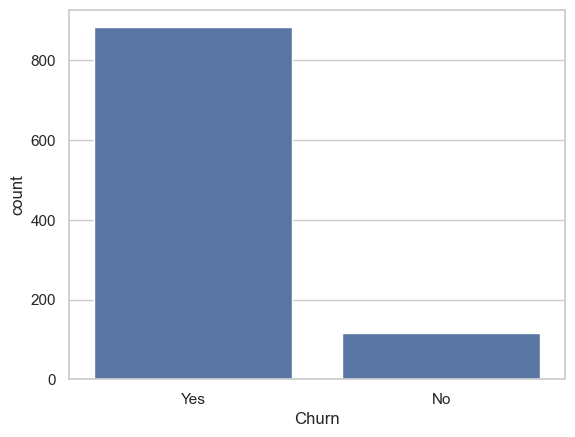

In [7]:
# visualising the balance between churned and retained customers
sns.countplot(data=customer_churn, x="Churn")

**Observation:** 883 of 1,000 customers churned (**88.3%**) and only 117 stayed.

**So what:**
- A churn rate this high is very unusual for a real business, which suggests this dataset is **synthetic** (generated by rules). I will keep that in mind and avoid presenting patterns as real-world behaviour.
- The data is **imbalanced**: the "stayed" group is small. When I compare groups I will use **rates**, not raw counts, and I will check group sizes before trusting a percentage.

## 4. One column at a time: categorical columns
How are customers split across each category?

In [8]:
# percentage of customers in each category
for col in cat_cols:
    print(f"Column: {col}")
    print((customer_churn[col].value_counts(normalize=True) * 100).round(1))
    print()

Column: Gender
Gender
Female    53.8
Male      46.2
Name: proportion, dtype: float64

Column: ContractType
ContractType
Month-to-Month    51.1
One-Year          28.9
Two-Year          20.0
Name: proportion, dtype: float64

Column: InternetService
InternetService
Fiber Optic    39.5
DSL            30.8
No Internet    29.7
Name: proportion, dtype: float64

Column: TechSupport
TechSupport
Yes    50.6
No     49.4
Name: proportion, dtype: float64



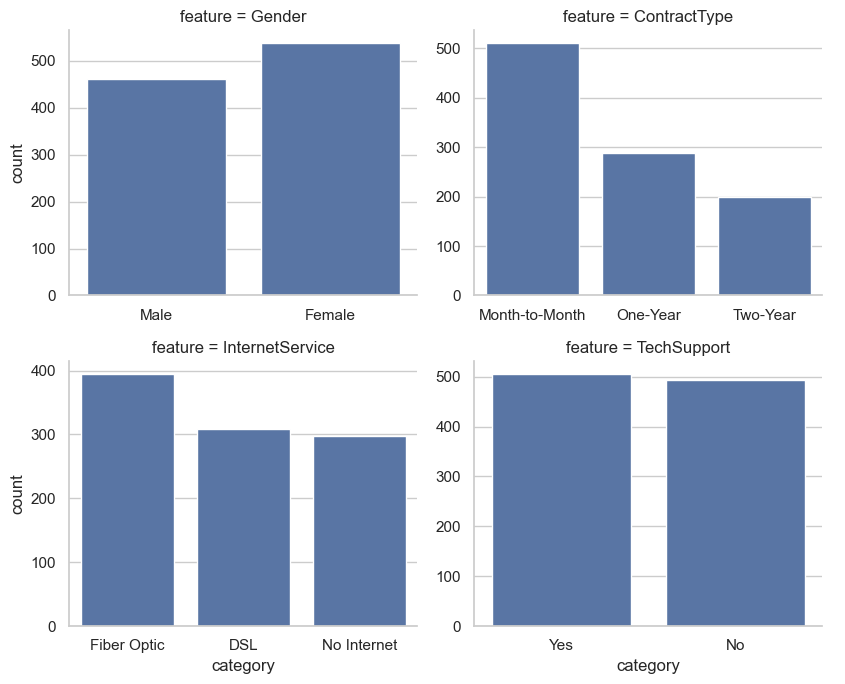

In [9]:
# one countplot per categorical column, using seaborn's col_wrap to build the subplots
long_cat = customer_churn.melt(value_vars=cat_cols, var_name="feature", value_name="category")

sns.catplot(data=long_cat, x="category", col="feature", kind="count",
            col_wrap=2, sharex=False, sharey=False, height=3.5, aspect=1.2)

**Observation:** the customer base is fairly balanced on gender (53.8% female) and tech support (50.6% yes). Just over half of customers (51.1%) are on Month-to-Month contracts, and 29.7% have no internet service.

**So what:** no category is so small that comparisons become meaningless, which makes the churn comparisons later more reliable.

## 5. One column at a time: numerical columns and outliers
I check the shape of each numerical column and look for unusual values. A dot beyond a boxplot whisker is only a **candidate** outlier, not automatically an error.

In [10]:
# summary statistics (CustomerID is excluded because the mean of an ID is meaningless)
customer_churn[num_cols].describe().round(2)

,Age,Tenure,MonthlyCharges,TotalCharges
count,1000.00,1000.00,1000.00,1000.00
mean,44.67,18.97,74.39,1404.36
std,9.80,18.89,25.71,1571.76
min,12.00,0.00,30.00,0.00
25%,38.00,5.00,52.36,345.22
50%,45.00,13.00,74.06,872.87
75%,51.00,26.00,96.10,1900.18
max,83.00,122.00,119.96,12416.25


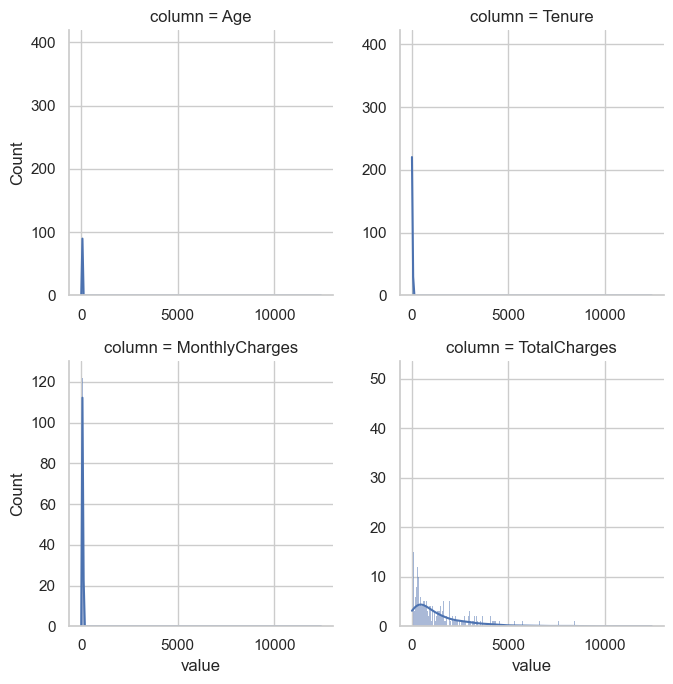

In [11]:
# reshaping to long format so seaborn can draw one plot per numerical column
long_num = customer_churn.melt(value_vars=num_cols, var_name="column", value_name="value")

# distribution of each numerical column
sns.displot(data=long_num, x="value", col="column", col_wrap=2, kde=True,
            facet_kws={"sharex": False, "sharey": False}, height=3.5)

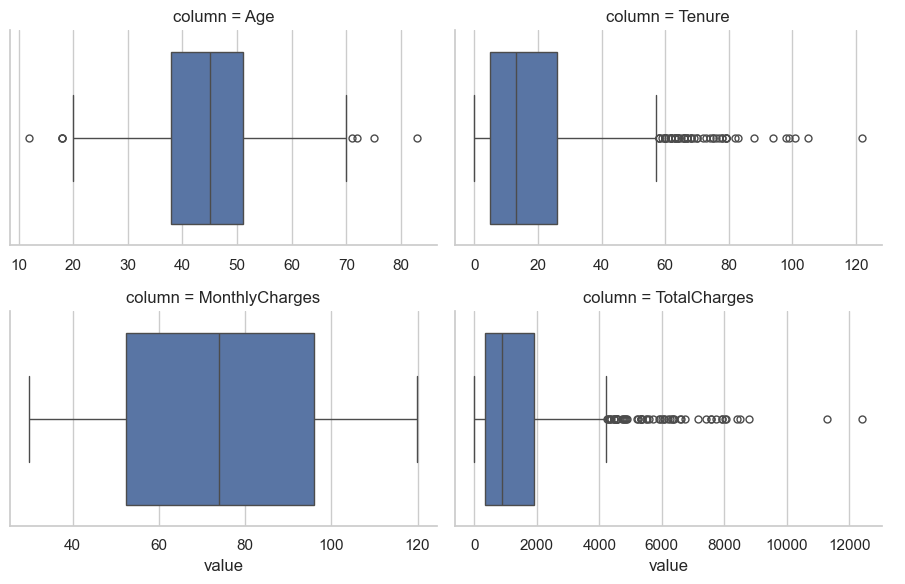

In [12]:
# boxplot of each numerical column to spot outliers
sns.catplot(data=long_num, x="value", col="column", kind="box",
            col_wrap=2, sharex=False, height=3, aspect=1.5)

In [13]:
# investigating the two unusual values I noticed in describe()
print("Customers under 18:")
display(customer_churn[customer_churn["Age"] < 18])

print("Customers with tenure above 72 months (6 years):", (customer_churn["Tenure"] > 72).sum())
print("Longest tenure:", customer_churn["Tenure"].max(), "months")

Customers under 18:


,CustomerID,Age,Gender,Tenure,MonthlyCharges,ContractType,InternetService,TotalCharges,TechSupport,Churn,Churn_Flag
262,263,12,Female,1,37.4,Two-Year,DSL,37.4,No,Yes,1


Customers with tenure above 72 months (6 years): 21
Longest tenure: 122 months


**Observation:**
- `Age` is roughly bell-shaped, centred around 45. `MonthlyCharges` is spread fairly evenly between 30 and 120. `Tenure` and `TotalCharges` are right-skewed: many newer customers and a few very long-term ones.
- **One customer is 12 years old**, which is unlikely for someone holding a service contract. 21 customers have tenure above 6 years, with a maximum of 122 months.

**Decision:** I am **keeping** these rows. There is only one under-18 record and the long tenures look like genuine long-term customers, so removing them would not change the findings. I will mention the age-12 record as a data-quality note.

## 6. Checking whether the columns agree with each other
`TotalCharges` should roughly equal `Tenure × MonthlyCharges`. If it does exactly, it adds no new information.

In [14]:
# how many rows do not match Tenure x MonthlyCharges?
diff = (customer_churn["Tenure"] * customer_churn["MonthlyCharges"] - customer_churn["TotalCharges"]).abs()
print("Rows where TotalCharges does not match:", (diff > 1).sum())
print("Customers with tenure = 0:", (customer_churn["Tenure"] == 0).sum())

Rows where TotalCharges does not match: 0
Customers with tenure = 0: 51


**Observation:** `TotalCharges` equals `Tenure × MonthlyCharges` in every row, and the 51 customers with zero tenure have zero total charges.

**So what:** `TotalCharges` is a **derived column**, so it will look strongly related to `Tenure` and carries no independent signal. I will rely on `Tenure` and `MonthlyCharges` for the analysis.

## 7. Categorical columns vs churn (the core of the EDA)
I use **rates** instead of counts because the groups are different sizes.

In [15]:
# churn rate (%) and group size for each category
for col in cat_cols:
    summary = customer_churn.groupby(col)["Churn_Flag"].agg(churn_rate="mean", customers="count")
    summary["churn_rate"] = (summary["churn_rate"] * 100).round(1)
    print(f"Column: {col}")
    print(summary)
    print()

Column: Gender
        churn_rate  customers
Gender                       
Female        87.4        538
Male          89.4        462

Column: ContractType
                churn_rate  customers
ContractType                         
Month-to-Month       100.0        511
One-Year              75.4        289
Two-Year              77.0        200

Column: InternetService
                 churn_rate  customers
InternetService                       
DSL                    84.4        308
Fiber Optic            82.5        395
No Internet           100.0        297

Column: TechSupport
             churn_rate  customers
TechSupport                       
No                100.0        494
Yes                76.9        506



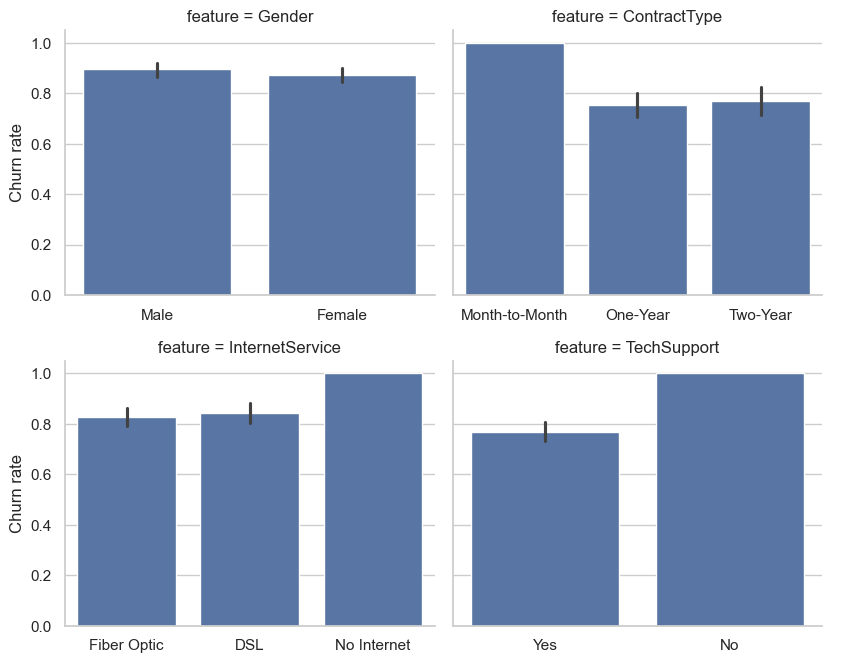

In [16]:
# bar charts of churn rate per category (the height of each bar is the average of Churn_Flag)
long_cat_churn = customer_churn.melt(id_vars="Churn_Flag", value_vars=cat_cols,
                                     var_name="feature", value_name="category")

g = sns.catplot(data=long_cat_churn, x="category", y="Churn_Flag", col="feature", kind="bar",
                col_wrap=2, sharex=False, height=3.5, aspect=1.2)
g.set_axis_labels("", "Churn rate")

In [17]:
# counts of churned vs retained customers: look for the groups where 'No' (retained) is 0
for col in ["ContractType", "InternetService", "TechSupport"]:
    print(pd.crosstab(customer_churn[col], customer_churn["Churn"]))
    print()

Churn           No  Yes
ContractType           
Month-to-Month   0  511
One-Year        71  218
Two-Year        46  154

Churn            No  Yes
InternetService         
DSL              48  260
Fiber Optic      69  326
No Internet       0  297

Churn         No  Yes
TechSupport          
No             0  494
Yes          117  389



**Observation:**
- **Month-to-Month: 100% churn** (511 of 511). One-Year (75.4%) and Two-Year (77.0%) are almost the same.
- **TechSupport = No: 100% churn** (494 of 494). With tech support: 76.9%.
- **No Internet: 100% churn** (297 of 297). DSL (84.4%) and Fiber Optic (82.5%) are similar.
- **Gender** makes almost no difference (female 87.4% vs male 89.4%).

**So what:**
- Three different groups have **zero** retained customers, which is a perfect pattern that real data rarely shows. This strongly supports the idea that the data was generated with rules.
- All 297 No Internet customers also have `TechSupport = No` (checked below), so I **cannot separate** the "no internet" effect from the "no tech support" effect.
- A longer contract only helps compared with Month-to-Month. Going from one year to two years makes no visible difference.

In [18]:
# are the 'No Internet' customers the same people as the 'No tech support' customers?
no_internet = customer_churn[customer_churn["InternetService"] == "No Internet"]
print(no_internet["TechSupport"].value_counts())

TechSupport
No    297
Name: count, dtype: int64


## 8. Numerical columns vs churn
Do churners and non-churners look different on age, tenure and price?

In [19]:
# average and median of each numerical column for churned vs retained customers
customer_churn.groupby("Churn")[["Age", "Tenure", "MonthlyCharges"]].agg(["mean", "median"]).round(1)

Age        Tenure        MonthlyCharges       
       mean median   mean median           mean median
Churn                                                 
No     43.5   44.0   30.3   25.0           62.5   60.6
Yes    44.8   45.0   17.5   11.0           76.0   78.6

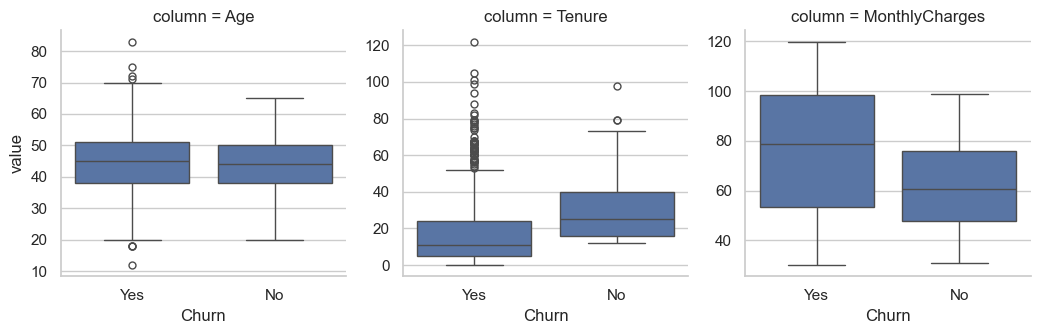

In [20]:
# boxplots comparing churned and retained customers, one plot per column
long_num_churn = customer_churn.melt(id_vars="Churn", value_vars=["Age", "Tenure", "MonthlyCharges"],
                                     var_name="column", value_name="value")

sns.catplot(data=long_num_churn, x="Churn", y="value", col="column", kind="box",
            sharey=False, height=3.5)

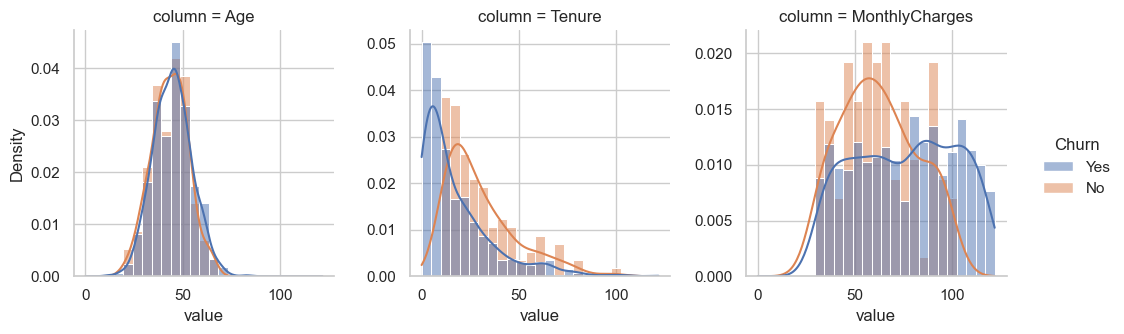

In [21]:
# overlapping distributions; stat="density" and common_norm=False fix the imbalance (883 vs 117)
# so the small 'No' group is not squashed
sns.displot(data=long_num_churn, x="value", hue="Churn", col="column", kde=True,
            stat="density", common_norm=False, facet_kws={"sharex": False, "sharey": False}, height=3.5)

In [22]:
# the smallest tenure among customers who stayed
print("Minimum tenure of retained customers:", customer_churn[customer_churn["Churn_Flag"] == 0]["Tenure"].min(), "months")
print("Churn rate for tenure under 12 months:",
      round(customer_churn[customer_churn["Tenure"] < 12]["Churn_Flag"].mean() * 100, 1), "%",
      "| customers:", (customer_churn["Tenure"] < 12).sum())

Minimum tenure of retained customers: 12 months
Churn rate for tenure under 12 months: 100.0 % | customers: 468


**Observation:**
- **Age** is nearly identical for churners (44.8 average) and non-churners (43.5), so it is not a useful driver.
- **Tenure:** retained customers average 30.3 months vs 17.5 for churners. **No customer with tenure under 12 months stayed** (468 customers, 100% churn).
- **MonthlyCharges:** churners pay more on average (about 76 vs 63 per month).

**So what:** the **first year is the danger zone**, and higher prices go with higher churn.

## 9. Relationships between numerical columns

<Axes: >

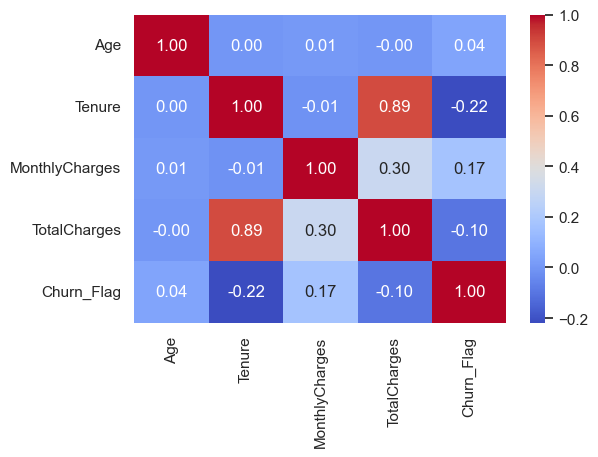

In [23]:
# correlation of the numerical columns with each other and with churn
plt.figure(figsize=(6, 4))
sns.heatmap(customer_churn[num_cols + ["Churn_Flag"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")

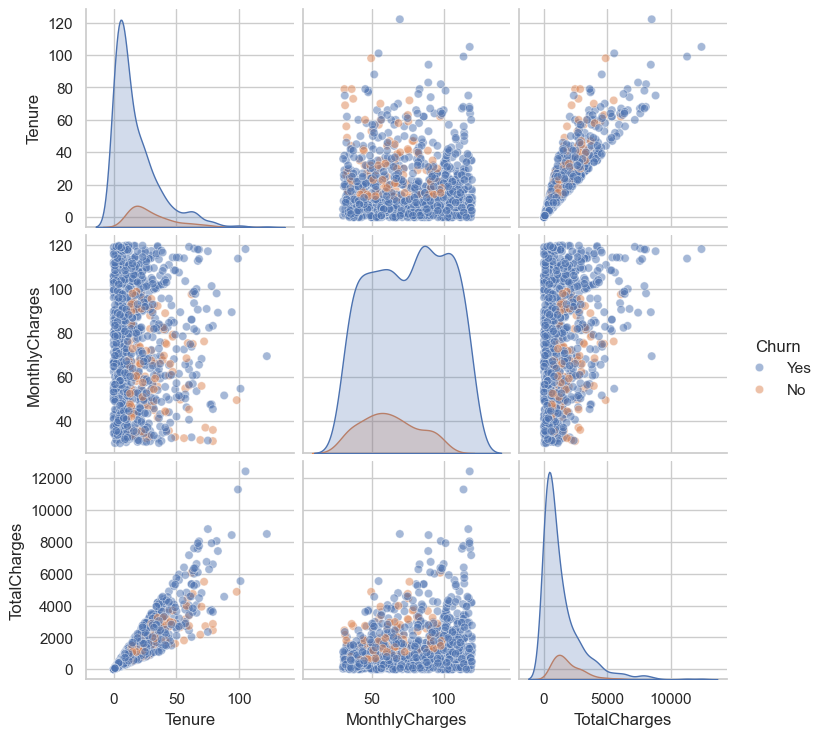

In [24]:
# scatter plots coloured by churn status (alpha makes overlapping points visible)
sns.pairplot(customer_churn, hue="Churn", vars=["Tenure", "MonthlyCharges", "TotalCharges"],
             plot_kws={"alpha": 0.5})

**Observation:** `Tenure` and `TotalCharges` are strongly correlated (0.89), as expected from section 6. Against churn, `Tenure` has a weak negative link (-0.22: longer tenure, less churn) and `MonthlyCharges` a weak positive link (0.17). Age has almost none (0.04).

**So what:** correlation shows association, not cause. Together with section 8, tenure and price are the two numerical factors worth showing on the dashboard.

## 10. Segments: which combinations are the highest risk?
Single columns can hide the real risk groups, so I combine two or more factors.

<Axes: xlabel='InternetService', ylabel='ContractType'>

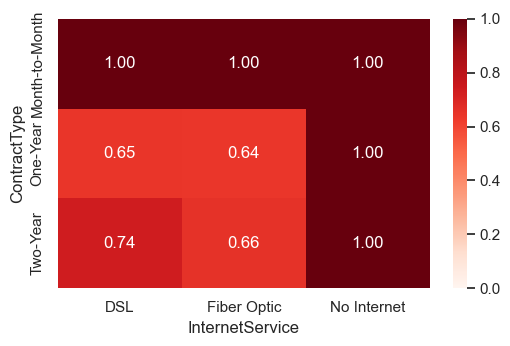

In [25]:
# churn rate by contract type and internet service
pivot = customer_churn.pivot_table(values="Churn_Flag", index="ContractType",
                                   columns="InternetService", aggfunc="mean").round(3)

plt.figure(figsize=(6, 3.5))
sns.heatmap(pivot, annot=True, cmap="Reds", fmt=".2f", vmin=0, vmax=1)

              mean  count
TenureGroup              
0-11 months  1.000    468
1-2 yrs      0.773    255
2-4 yrs      0.780    191
4+ yrs       0.802     86


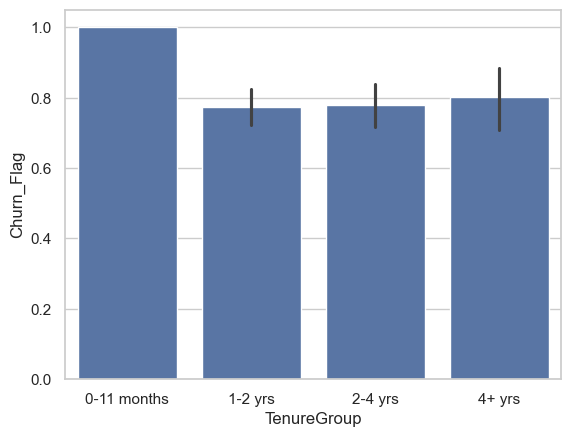

In [26]:
# tenure groups (these will also be created in Power BI)
customer_churn["TenureGroup"] = pd.cut(customer_churn["Tenure"], bins=[-1, 11, 24, 48, 200],
                                       labels=["0-11 months", "1-2 yrs", "2-4 yrs", "4+ yrs"])

sns.barplot(data=customer_churn, x="TenureGroup", y="Churn_Flag")
print(customer_churn.groupby("TenureGroup", observed=True)["Churn_Flag"].agg(["mean", "count"]).round(3))

            mean  count
PriceTier              
Low        0.838    333
Mid        0.865    334
High       0.946    333


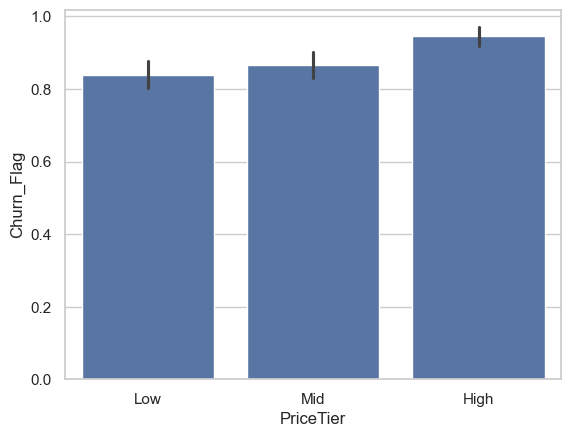

In [27]:
# monthly charge tiers (low / mid / high thirds of the price range)
customer_churn["PriceTier"] = pd.qcut(customer_churn["MonthlyCharges"], q=3, labels=["Low", "Mid", "High"])

sns.barplot(data=customer_churn, x="PriceTier", y="Churn_Flag")
print(customer_churn.groupby("PriceTier", observed=True)["Churn_Flag"].agg(["mean", "count"]).round(3))

**Observation:** every Month-to-Month and No Internet combination churns at 100%. The only cells below 100% are One-Year and Two-Year contracts with DSL or Fiber (about 64% to 74%). Churn also rises with price tier (83.6% low, 86.7% mid, 94.6% high).

**So what:** most of the "risk" is spread across obvious groups, so the interesting question is: **what is left once I remove the groups that always churn?**

### Drill-down: the customers who are *not* in an always-churn group
I flag customers who are Month-to-Month, **or** have no tech support, **or** have no internet, **or** have tenure under 12 months. Then I check the churn rate inside and outside that flag.

In [28]:
# 'always-churn' profile based on the patterns found above
always_churn = ((customer_churn["ContractType"] == "Month-to-Month")
                | (customer_churn["TechSupport"] == "No")
                | (customer_churn["InternetService"] == "No Internet")
                | (customer_churn["Tenure"] < 12))

print("Customers in an always-churn group:", always_churn.sum(),
      "| churn rate:", round(customer_churn[always_churn]["Churn_Flag"].mean() * 100, 1), "%")

stable = customer_churn[~always_churn]
print("Remaining customers:", len(stable),
      "| churn rate:", round(stable["Churn_Flag"].mean() * 100, 1), "%")

Customers in an always-churn group: 857 | churn rate: 100.0 %
Remaining customers: 143 | churn rate: 18.2 %


In [29]:
# inside the remaining 143 customers, what separates churners from those who stayed?
print(stable.groupby("Churn")[["Tenure", "MonthlyCharges", "Age"]].mean().round(1))
print()
print(stable.groupby("PriceTier", observed=True)["Churn_Flag"].agg(["mean", "count"]).round(3))
print()
print(stable.groupby("TenureGroup", observed=True)["Churn_Flag"].agg(["mean", "count"]).round(3))

       Tenure  MonthlyCharges   Age
Churn                              
No       30.3            62.5  43.5
Yes      25.7           108.4  42.6

            mean  count
PriceTier              
Low        0.000     54
Mid        0.000     45
High       0.591     44

              mean  count
TenureGroup              
1-2 yrs      0.216     74
2-4 yrs      0.160     50
4+ yrs       0.105     19


**Observation:**
- **857 customers (85.7%) fall in an always-churn group and every one of them churned.**
- The other **143 customers** churn at **18.2%**. Inside this group, **price is what separates them**: churners pay about 108 per month vs 63 for those who stayed, and **all churn happens in the high-price tier** (59% of that tier churns; low and mid tiers: 0%).
- Within this group, longer tenure goes with lower churn (21.6% for 1 to 2 years, 16.0% for 2 to 4 years, 10.5% for 4+ years).

**So what:** after removing the rule-driven groups, the only remaining signal is **high monthly price**, and the retention story is mainly about the first year and about price. These findings come from a small group (143), so I treat them as **directional**, not conclusive.

## 11. Business impact: revenue at risk

In [30]:
# monthly revenue from churned customers vs total monthly revenue
revenue_at_risk = customer_churn.loc[customer_churn["Churn_Flag"] == 1, "MonthlyCharges"].sum()
total_revenue = customer_churn["MonthlyCharges"].sum()
print("Monthly revenue from churned customers:", round(revenue_at_risk))
print("Total monthly revenue:", round(total_revenue))
print("Share of revenue lost:", round(revenue_at_risk / total_revenue * 100, 1), "%")

Monthly revenue from churned customers: 67073
Total monthly revenue: 74391
Share of revenue lost: 90.2 %


**Observation:** churned customers account for about 90% of monthly revenue, slightly more than their 88% share of customers, because they pay more on average.

**So what:** this becomes the **Revenue at Risk** KPI card in Power BI.

## 12. Data limitations to mention in my report
- **Synthetic-looking data:** the perfect 100% churn groups and the 88% overall churn rate are not realistic, so conclusions should not be presented as real-world customer behaviour.
- **Overlapping factors:** no-internet and no-tech-support customers are the same people, so their effects cannot be separated.
- **Small comparison group:** only 117 customers stayed, so differences between small subgroups are uncertain.
- **Correlation is not cause:** a link between price and churn does not prove that price causes churn.
- **Data-quality note:** one customer is 12 years old.

## 13. Key findings

1. **Overall churn is 88.3%** (883 of 1,000), far above what a real business would see, and the data is heavily imbalanced.
2. **Month-to-Month contracts, no tech support, and no internet service each have 100% churn.** One-Year and Two-Year contracts churn at about the same rate (75% vs 77%).
3. **The first year is the danger zone:** no customer with under 12 months of tenure stayed (468 customers).
4. **Gender and age do not drive churn** (87% vs 89% by gender; average age 43.5 for retained vs 44.8 for churned).
5. **Higher monthly price goes with higher churn** (churn rate 84% low, 87% mid, 95% high price tier). Among customers outside the always-churn groups, all churn happens in the high-price tier.
6. **Churned customers hold about 90% of monthly revenue** (about 67,000 of 74,000).
7. **`TotalCharges` is derived** from tenure and monthly charges, so it adds no new information.

## Handoff to Power BI
| Item | Details |
|---|---|
| **KPI cards** | Total Customers, Churn Rate %, Revenue at Risk |
| **Charts** | Churn rate by Contract, by Tenure Group, by Price Tier; Contract × Internet heatmap (matrix visual) |
| **Slicers** | ContractType, InternetService, TechSupport, TenureGroup |
| **Columns to export** | All cleaned columns plus `Churn_Flag`, `TenureGroup`, `PriceTier` |
| **Caveat** | Add a note on the dashboard that the data appears synthetic |

## Next steps
- Build the Power BI model and DAX measures (Total Customers, Churned Customers, Churn Rate %, Revenue at Risk)
- Write a one-page summary of these findings for my supervisor